In [ ]:
import sys, os
import numpy as np
from datasets import load_dataset
from pathlib import Path
from typing import  Optional



project_root = os.path.abspath(os.path.join(os.getcwd(),'..'))
print(project_root)
sys.path.append(project_root)

from vlas.openvlaOFT.openvla_utils import get_action_head, get_processor, get_proprio_projector, get_vla, get_vla_action
# from vlas.openvlaOFT.action_tokenizer import ActionTokenizer

from vlas.openvlaOFT.constants import (
    ACTION_DIM,
    NUM_ACTIONS_CHUNK,
    PROPRIO_DIM,
)
from dataclasses import dataclass
from src.utils.logger import get_logger
logger = get_logger(__name__)


/home/user/project/objectvla


In [5]:
@dataclass
class EvalConfig:
    # fmt: off
    # pretrained_checkpoint: str = "../vlas/checkpoints/openvla-7b-oft-finetuned-libero-spatial-object-goal-10"             # Path to OpenVLA model (on HuggingFace Hub or stored locally)
    pretrained_checkpoint: str = "../vlas/checkpoints/openvla-7b-oft-finetuned-libero-object"             # Path to OpenVLA model (on HuggingFace Hub or stored locally)
    # pretrained_checkpoint: str = "../vlas/checkpoints/openvla-7b"             # Path to OpenVLA model (on HuggingFace Hub or stored locally)

    # Dataset
    data_dir: Path = Path("../mydatasets/amylingchen/libero_object_no_noops_1.0.0_lerobot")      # Directory containing RLDS datasets
    repo_id: str = "amylingchen/libero_object_no_noops_1.0.0_lerobot"   # Name of fine-tuning dataset (e.g., `aloha_scoop_x_into_bowl`)
    run_root_dir: Path = Path("../mydatasets/openvlaoft/libero_object/embeddings")                # Path to directory to store logs & checkpoints
    shuffle_buffer_size: int = 100_000               # Dataloader shuffle buffer size (can reduce if OOM errors occur)

    # Algorithm and architecture
    use_l1_regression: bool = True                   # If True, trains continuous action head with L1 regression objective
    use_diffusion: bool = False                      # If True, trains continuous action head with diffusion modeling objective (DDIM)
    num_diffusion_steps_train: int = 50              # (When `diffusion==True`) Number of diffusion steps used for training
    use_film: bool = False                           # If True, uses FiLM to infuse language inputs into visual features
    num_images_in_input: int = 2                     # Number of images in the VLA input (default: 1)
    use_proprio: bool = False                        # If True, includes robot proprioceptive state in input

    # Training configuration
    batch_size: int = 2                              # Batch size per device (total batch size = batch_size * num GPUs)
    learning_rate: float = 5e-4                      # Learning rate
    lr_warmup_steps: int = 0                         # Number of steps to warm up learning rate (from 10% to 100%)
    num_steps_before_decay: int = 100_000            # Number of steps before LR decays by 10x
    grad_accumulation_steps: int = 1                 # Number of gradient accumulation steps
    max_steps: int = 200_000                         # Max number of training steps
    use_val_set: bool = False                        # If True, uses validation set and log validation metrics
    val_freq: int = 10_000                           # (When `use_val_set==True`) Validation set logging frequency in steps
    val_time_limit: int = 180                        # (When `use_val_set==True`) Time limit for computing validation metrics
    save_freq: int = 10_000                          # Checkpoint saving frequency in steps
    save_latest_checkpoint_only: bool = False        # If True, saves only 1 checkpoint, overwriting latest checkpoint
                                                     #   (If False, saves all checkpoints)
    resume: bool = False                             # If True, resumes from checkpoint
    resume_step: Optional[int] = None                # (When `resume==True`) Step number that we are resuming from
    image_aug: bool = True                           # If True, trains with image augmentations (HIGHLY RECOMMENDED)
    diffusion_sample_freq: int = 50                  # (When `use_diffusion==True`) Frequency for sampling in steps

    load_in_8bit: bool = False
    load_in_4bit:bool = False
    image_size: int = 224
    center_crop: bool = True
    unnorm_key = 'libero_object_no_noops'
    num_open_loop_steps = 8

cfg = EvalConfig()

In [6]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [7]:
def load_openvla_model( cfg):
    logger.info(
        f"Loading OpenVLA-OFT model from {  cfg.pretrained_checkpoint}"
    )

    processor = get_processor(cfg)
    vla = get_vla(cfg, device=device)

    action_head = get_action_head(
        cfg, llm_dim=vla.llm_dim, device=device
    )
    proprio_projector = get_proprio_projector(
        cfg,
        llm_dim=vla.llm_dim,
        proprio_dim=PROPRIO_DIM,
        device=device,
    )

    logger.info("OpenVLA-OFT model loaded")
    return vla, processor, action_head, proprio_projector

In [8]:
# Instantiate config (see class GenerateConfig in experiments/robot/libero/run_libero_eval.py for definitions)

# Load OpenVLA-OFT policy and inputs processor
vla, processor, action_head, proprio_projector = load_openvla_model(cfg)


Expected `transformers==4.40.1` and `tokenizers==0.19.1` but got `transformers==4.41.2` and `tokenizers==0.19.1`; there might be inference-time regressions due to dependency changes. If in doubt, pleaseuse the above versions.


Instantiating pretrained VLA policy...
Created backup of original config at: /home/user/project/objectvla/vlas/checkpoints/openvla-7b-oft-finetuned-libero-object/config.json.back.20260305_045930
Updated config.json at: /home/user/project/objectvla/vlas/checkpoints/openvla-7b-oft-finetuned-libero-object/config.json
Changes made:
  - Set AutoConfig to "configuration_prismatic.OpenVLAConfig"
  - Set AutoModelForVision2Seq to "modeling_prismatic.OpenVLAForActionPrediction"


Loading checkpoint shards: 100%|██████████| 4/4 [00:33<00:00,  8.48s/it]


In [9]:
# Load MLP action head to generate continuous actions (via L1 regression)
action_head = get_action_head(cfg, llm_dim=vla.llm_dim)
# Load proprio projector to map proprio to language embedding space
proprio_projector = get_proprio_projector(cfg, llm_dim=vla.llm_dim, proprio_dim=PROPRIO_DIM)

# Load sample observation:
#   observation (dict): {
#     "full_image": primary third-person image,
#     "wrist_image": wrist-mounted camera image,
#     "state": robot proprioceptive state,
#     "task_description": task description,
#   }
# with open("../mydatasets/libero/sample_libero_spatial_observation.pkl", "rb") as file:
#     observation = pickle.load(file)


In [85]:
from datasets import load_dataset
from src.utils.libero_utils import resize_image
from PIL import Image
# Login using e.g. `huggingface-cli login` to access this dataset
ds = load_dataset("lerobot/libero_object_image", cache_dir="../mydatasets/amylingchen/libero")
data_index = 5
data = ds["train"][data_index]
task_index = data['task_index']

image_pil = data['observation.images.image']  # PIL.Image

# 转成 Tensor 并调整通道顺序 (HWC -> CHW)
img1 = resize_image(image_pil, (cfg.image_size, cfg.image_size))

img2 = resize_image(data['observation.images.wrist_image'],(cfg.image_size, cfg.image_size))
# wirst_image_tensor = torch.from_numpy(np.array(data['observation.images.wrist_image'])/255.0).to(device).float()
print(img1.shape, img2.shape,img1.dtype,img2.dtype)

object = 'cream cheese'

observation = {
    "observation.state": data['observation.state'],
    'observation.images.image': img1,
    'observation.images.wrist_image': img2,
    # "task": [f'pick up the {object} and place it in the basket'], 
    "task": [f'{object}'], 
}

(224, 224, 3) (224, 224, 3) uint8 uint8


In [86]:
data

{'observation.images.image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=256x256>,
 'observation.images.wrist_image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=256x256>,
 'observation.state': [-0.15244629979133606,
  -0.0002454198547638953,
  0.26688846945762634,
  3.1297802925109863,
  -0.029546024277806282,
  -0.08590351045131683,
  0.03906488046050072,
  -0.03906923905014992],
 'action': [0.23035714030265808,
  0.0,
  -0.0,
  -0.05249999836087227,
  -0.007499999832361937,
  -0.03214285895228386,
  -1.0],
 'timestamp': 0.5,
 'frame_index': 5,
 'episode_index': 0,
 'index': 5,
 'task_index': 0}

In [87]:
observation['observation.images.image'].shape,observation['observation.images.wrist_image'].shape,observation['observation.state']

((224, 224, 3),
 (224, 224, 3),
 [-0.15244629979133606,
  -0.0002454198547638953,
  0.26688846945762634,
  3.1297802925109863,
  -0.029546024277806282,
  -0.08590351045131683,
  0.03906488046050072,
  -0.03906923905014992])

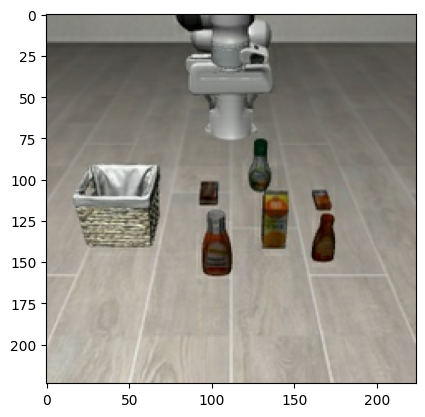

In [88]:
import matplotlib.pyplot as plt
plt.imshow(img1)


(<PIL.PngImagePlugin.PngImageFile image mode=RGB size=256x256>,
 <matplotlib.image.AxesImage at 0x7f6d8c7ba830>)

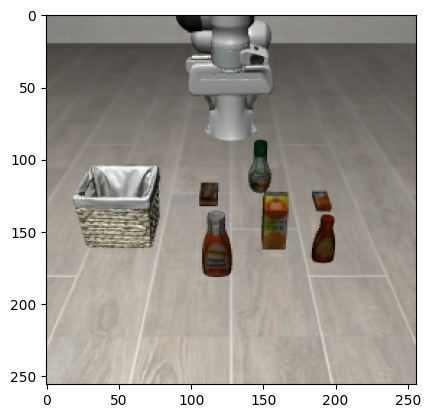

In [89]:
image_pil,plt.imshow(image_pil)

In [90]:
import torch
import gc
gc.collect()
torch.cuda.empty_cache()

In [91]:
actions, actions_hidden_states,normalized_actions,_,attentions  = get_vla_action(cfg, vla, processor, 
                                                                               observation, 
                                                                               observation["task"][0], 
                                                                               action_head, 
                                                                               proprio_projector,
                                                                               output_attention=True,
                                                                               )
print("Generated action chunk:")
action,hidden_state, normalized_action = actions[0], actions_hidden_states[0,:7], normalized_actions[0]
print("Action:", action)
print("Normalized action:", normalized_action)
print("Hidden states:", hidden_state)
actions_hidden_states

Primary pixel values shape: torch.Size([1, 6, 224, 224])
Primary language input shape: torch.Size([1, 18])
256 2
Generated action chunk:
Action: [0.218 -0.114 0.033 -0.008 0.013 -0.021 0.738]
Normalized action: [0.092 -0.114 0.035 -0.181 -0.022 0.128 0.738]
Hidden states: tensor([[ 2.1719,  0.0723,  0.5703,  ..., -0.5625,  2.2812, -0.3281],
        [ 0.6562,  1.3906,  0.6523,  ..., -0.4453,  1.3594,  0.3418],
        [ 0.5273,  1.1562,  1.3672,  ..., -0.8984,  1.7578,  0.1895],
        ...,
        [ 0.9727,  0.7578,  1.2266,  ..., -0.7305,  1.9375,  0.4238],
        [ 0.7266,  1.3672,  1.2266,  ..., -0.3379,  1.6641, -0.0217],
        [ 0.6289,  1.2500,  1.5469,  ..., -0.2041,  2.0625,  0.6484]],
       device='cuda:0', dtype=torch.bfloat16)


tensor([[[ 2.1719,  0.0723,  0.5703,  ..., -0.5625,  2.2812, -0.3281],
         [ 0.6562,  1.3906,  0.6523,  ..., -0.4453,  1.3594,  0.3418],
         [ 0.5273,  1.1562,  1.3672,  ..., -0.8984,  1.7578,  0.1895],
         ...,
         [ 0.7266,  1.3672,  1.2266,  ..., -0.3379,  1.6641, -0.0217],
         [ 0.6289,  1.2500,  1.5469,  ..., -0.2041,  2.0625,  0.6484],
         [ 0.7227,  0.9609,  1.3672,  ..., -0.5625,  2.0625, -0.0894]]],
       device='cuda:0', dtype=torch.bfloat16)

(tensor(1., device='cuda:0', dtype=torch.float64),
 tensor(0., device='cuda:0', dtype=torch.float64),
 torch.Size([1, 32, 588, 588]))

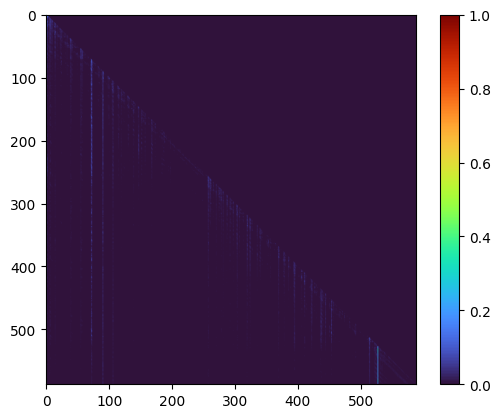

In [92]:
mean_attention = attentions[-1].mean(dim=1).squeeze(0).to(float)  # Average over heads
plt.imshow(mean_attention.cpu().numpy(), cmap='turbo')
plt.colorbar()
plt.savefig(f'openvlaoft/{data_index}_{object.replace(" ", "_")}_mean_attention_map_last_layer.png')
mean_attention.max(), mean_attention.min(),attentions[-1].shape



In [93]:
mean_attention[538],len(mean_attention)

(tensor([3.2227e-01, 2.3651e-03, 5.1880e-03, 5.6076e-04, 2.4796e-04, 2.6703e-03,
         2.8992e-03, 2.0905e-03, 8.8882e-04, 1.0147e-03, 1.1520e-03, 1.6403e-04,
         1.0300e-04, 4.5776e-04, 3.2349e-03, 2.7847e-04, 1.0920e-04, 9.3079e-04,
         5.7220e-04, 3.8147e-04, 4.3869e-04, 3.2616e-04, 1.8692e-03, 1.0223e-03,
         4.2152e-04, 2.1362e-04, 3.5667e-04, 1.7738e-04, 7.5340e-05, 3.3569e-04,
         3.0327e-04, 4.4250e-04, 2.0504e-04, 1.4343e-03, 1.0300e-03, 1.7700e-03,
         1.6117e-04, 8.9169e-05, 1.0071e-03, 2.1667e-03, 1.3275e-03, 1.5106e-03,
         7.6675e-04, 1.3733e-04, 1.6809e-05, 1.0681e-04, 1.8024e-04, 1.4591e-04,
         8.7738e-05, 1.2283e-03, 5.3167e-05, 1.8024e-04, 1.0633e-04, 3.8147e-05,
         5.1880e-04, 2.8992e-03, 1.0986e-03, 1.2741e-03, 1.2054e-03, 1.3351e-04,
         1.2398e-04, 7.7057e-04, 5.0354e-04, 3.8719e-04, 1.8978e-04, 4.8447e-04,
         4.9353e-05, 1.6689e-04, 5.0068e-05, 8.6308e-05, 1.8311e-04, 3.2654e-03,
         2.1362e-02, 7.4768e

In [94]:
project_root = os.path.abspath(os.path.join(os.getcwd(),'..'))
sys.path.append(project_root)
project_root

'/home/user/project/objectvla'

In [95]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

def generate_attention_heatmap(images, attn_weights,
                               action_token_idx=-1, 
                               image_token_slice=slice(0, 256),
                               layer_idx=-1, 
                               head_idx=None):
    """
    生成attention heatmap并叠加到原始图像上
    
    Args:
        images: 原始图像列表 [batch_size, channels, height, width]
        attn_weights: attention权重列表
        layer_idx: 使用哪一层的attention权重（默认最后一层）
        head_idx: 使用哪个attention head（默认第一个head）
    """
    
    # 获取最后一层的attention权重
    layer_attn = attn_weights[layer_idx].to(float)
    
    # 选择特定的attention head
    # 假设attn_weights的形状为: [batch_size, num_heads, seq_len, seq_len]
    batch_size = layer_attn.shape[0]
    
    heatmaps = []
    
    for batch_idx in range(batch_size):
        # 获取当前batch的attention权重
        batch_attn = layer_attn[batch_idx]
        
        # 选择特定的head
        if head_idx is not None:
            head_attn = batch_attn[head_idx]
        else:
            head_attn = batch_attn.mean(dim=0, keepdim=True).squeeze(0)
        
        num_image_tokens = image_token_slice.stop - image_token_slice.start
        
        image_attentions = head_attn[action_token_idx, image_token_slice.start:image_token_slice.stop]
        
        # 将1D的attention权重重塑为2D网格
        # 假设图像被分割为16x16的patch（共256个patch）
        grid_size = int(np.sqrt(num_image_tokens))
        heatmap_2d = image_attentions.reshape(grid_size, grid_size).cpu().numpy()
        
        # 上采样到原始图像大小
        original_height, original_width = images[0].shape[0:2]
        heatmap_resized = cv2.resize(
            heatmap_2d, 
            (original_width, original_height), 
            interpolation=cv2.INTER_LINEAR
        )
        
        # 归一化到[0, 1]
        heatmap_normalized = (heatmap_resized - heatmap_resized.min()) / \
                             (heatmap_resized.max() - heatmap_resized.min() + 1e-8)
        
        # 将heatmap转换为彩色
        heatmap_colored = cv2.applyColorMap(
            np.uint8(255 * heatmap_normalized), 
            cv2.COLORMAP_JET
        )
        
        # 转换图像格式（从[-1, 1]到[0, 255]）
        original_img = images[batch_idx].astype(np.uint8)
        
        # 叠加heatmap到原始图像
        alpha = 0.3  # 透明度
        overlay = cv2.addWeighted(
            original_img, 
            1 - alpha, 
            heatmap_colored, 
            alpha, 
            0
        )
        
        heatmaps.append({
            'heatmap': heatmap_resized,
            'overlay': overlay,
            'original': original_img
        })
    
    return heatmaps


def visualize_attention_heads(
    img_batch,
    attentions,
    action_token_idx,
    image_token_slice,
    layer_idx=-1,
    num_heads=32,
    n_rows=7,
    n_cols=5,
    figsize=(15, 21),
    title=None
):
    """
    Generate and visualize attention heatmaps for each head.

    Args:
        img_batch: np.ndarray, shape [1, H, W, C]
        attentions: list of attention tensors
        action_token_idx: int
        image_token_slice: slice
        layer_idx: int
        num_heads: number of attention heads
        n_rows, n_cols: subplot layout
        figsize: matplotlib figure size
    """

    heatmaps = []

    # 1️⃣ 生成每个 head 的 heatmap
    for head_idx in range(num_heads):
        heatmap = generate_attention_heatmap(
            img_batch,
            attentions,
            action_token_idx=action_token_idx,
            image_token_slice=image_token_slice,
            layer_idx=layer_idx,
            head_idx=head_idx,
            
        )
        heatmaps.append(heatmap)

    # 2️⃣ 画 grid
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    axes = axes.flatten()

    for idx, ax in enumerate(axes):
        if idx < len(heatmaps):
            ax.imshow(heatmaps[idx][0]["overlay"])
            ax.set_title(f"head: {idx},max:{heatmaps[idx][0]['heatmap'].max():.4f}", fontsize=11)
            ax.axis("off")
        else:
            ax.axis("off")

    plt.tight_layout()
    if title is not None:
        plt.savefig(f'{title}.png')
    else:
        plt.show()

In [96]:
# from src.utils.heatmap_for_vla import generate_attention_heatmap
action_idx = len(mean_attention)-59
print(action_idx)

img_batch = np.expand_dims(img1, axis=0)
# visualize_attention_heads(img_batch, attentions,
                            # action_token_idx=action_idx,
                            # image_token_slice=slice(1, 257),
                            # layer_idx=-1,
                            # num_heads=32,
                            # title=f'JAN/heatmap_last_layer_{object.replace(" ", "_")}_{data_index}_1')




529


In [97]:
# from src.utils.heatmap_for_vla import generate_attention_heatmap
language_idx = len(mean_attention)-69
print(language_idx)
img_batch2 = np.expand_dims(img2, axis=0)

519


(0.022684312850417776, 1.4761837291083729e-05)

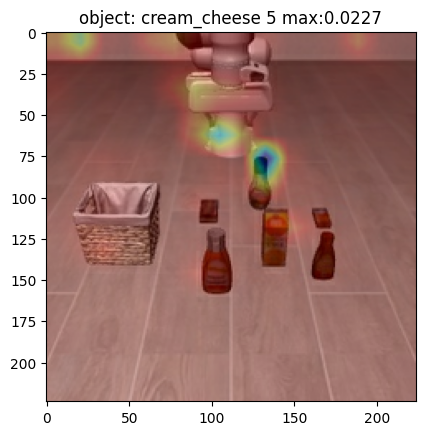

In [98]:
heatmap = generate_attention_heatmap(img_batch, attentions,
                               action_token_idx=language_idx, 
                               image_token_slice=slice(1, 257),
                         layer_idx=-1, 
                         head_idx=None)
plt.imshow(heatmap[0]['overlay'])
plt.title(
    f"object: {object.replace(' ', '_')} {data_index} "
    f"max:{heatmap[0]['heatmap'].max():.4f}"
)
# plt.colorbar()
plt.savefig(f'openvlaoft/{data_index}_{object.replace(" ", "_")}_heatmap_mean_object_1.png')
heatmap[0]['heatmap'].max(), heatmap[0]['heatmap'].min()

(0.017123996828354856, 1.3127106126173e-05)

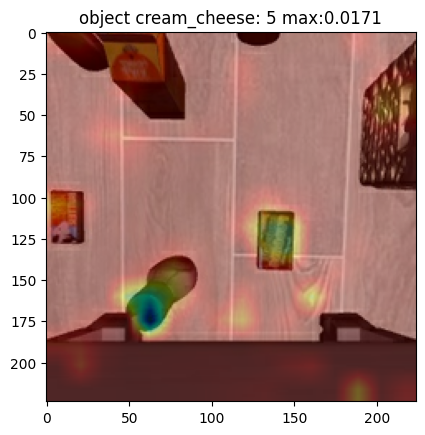

In [99]:
heatmap_wrist = generate_attention_heatmap(img_batch2, attentions,
                               action_token_idx=language_idx, 
                               image_token_slice=slice(257, 513),
                         layer_idx=-1, 
                         head_idx=None)
plt.imshow(heatmap_wrist[0]['overlay'])
plt.title(
    f"object {object.replace(' ', '_')}: {data_index} "
    f"max:{heatmap_wrist[0]['heatmap'].max():.4f}"
)
# plt.colorbar()
plt.savefig(f'openvlaoft/{data_index}_{object.replace(" ", "_")}_heatmap_mean_object_2.png')

heatmap_wrist[0]['heatmap'].max(), heatmap_wrist[0]['heatmap'].min()

In [100]:

def compute_attention_heatmap(
    attention_1d,
    grid_size,
    original_image,
    normalize=True,
    alpha=0.3,
):
    """
    输入:
        attention_1d: (num_patches,)
        grid_size: patch grid size (e.g. 16, 24)
        original_image: (H, W, C) or (H, W)

    输出:
        heatmap: (H, W) float32 heatmap
    """
    # 1. patch → grid
    attention_grid = attention_1d.reshape(grid_size, grid_size)

    # 2. resize 到原图大小
    h, w = original_image.shape[:2]
    heatmap = cv2.resize(
        attention_grid,
        (w, h),
        interpolation=cv2.INTER_LINEAR
    )

    # 3. 归一化（可选）
    if normalize:
        heatmap = (heatmap - heatmap.min()) / \
                  (heatmap.max() - heatmap.min() + 1e-8)
        
    heatmap = cv2.applyColorMap( np.uint8(255 * heatmap), cv2.COLORMAP_JET )    
    overlay = cv2.addWeighted(
        original_image, 
        1 - alpha, 
        heatmap, 
        alpha, 
        0
    )

    return overlay


def plot_mean_attention(
    importance_heatmap,
    object,
    data_index,
    idx,
    max_value=0
):
    plt_title = f'openvlaoft/{data_index}_{object.replace(" ", "_")}_heatmap_mean__{idx}'
    plt.imshow(importance_heatmap, cmap='turbo')
    plt.title(
        f"{object.replace(' ', '_')} {data_index} "
        f"max:{max_value :.4f}"
    )
    # plt.colorbar()
    plt.savefig(f'{plt_title}.png')

In [101]:
def analyze_multi_object_attention(attention_map, token_info,original_image=None, object='', data_index=0,idx =1):
    """
    分析多物体场景下的attention分布
    """
    # 提取action token对图像的attention
    action_to_image = attention_map[
        token_info['action_start']:token_info['action_end'],
        token_info['image_start']:token_info['image_end']
    ]
    
    num_actions = action_to_image.shape[0]
    num_patches = action_to_image.shape[1]
    grid_size = int(np.sqrt(num_patches))
    
    # 计算每个patch被所有action token关注的总强度
    patch_importance = action_to_image.sum(axis=0)
    
    # 重塑为2D网格
    importance_grid = patch_importance.reshape(grid_size, grid_size)
    
    # 计算attention的集中度（使用Gini系数）
    sorted_attention = np.sort(patch_importance)
    n = len(sorted_attention)
    cum_attention = np.cumsum(sorted_attention)
    gini = (n + 1 - 2 * np.sum(cum_attention) / cum_attention[-1]) / n
    
    print(f"Attention Gini系数: {gini:.4f}")
    print(f"Top-5 patches占据总attention的: {sorted_attention[-5:].sum()/sorted_attention.sum()*100:.1f}%")
    
    # 分析多峰值现象
    from scipy.signal import find_peaks
    peaks, properties = find_peaks(patch_importance, 
                                  height=np.percentile(patch_importance, 75))
    
    print(f"发现 {len(peaks)} 个attention峰值")

    importance_heatmap = compute_attention_heatmap(
            attention_1d=patch_importance,
            grid_size=grid_size,
            original_image=original_image,
            normalize=True,
            alpha=0.3,
        )
    plot_mean_attention(
        importance_heatmap=importance_heatmap,
        object=object,
        data_index=data_index,
        idx=idx,
        max_value=patch_importance.max()/num_actions
        )
    
    # 可视化
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    

    # # 1. attention热力图
    # im1 = axes[0, 0].imshow(importance_heatmap, cmap='YlOrRd')
    # axes[0, 0].set_title('Overall Attention Heatmap')
    # axes[0, 0].axis('off')
    # plt.colorbar(im1, ax=axes[0, 0])
    
    # # 2. attention分布直方图
    # axes[0, 1].hist(patch_importance, bins=50, alpha=0.7)
    # axes[0, 1].axvline(x=np.median(patch_importance), color='r', 
    #                   linestyle='--', label=f'Median: {np.median(patch_importance):.4f}')
    # axes[0, 1].set_xlabel('Attention Value')
    # axes[0, 1].set_ylabel('Frequency')
    # axes[0, 1].set_title('Attention Distribution')
    # axes[0, 1].legend()
    # axes[0, 1].grid(True)
    
    # 3. 不同action token的关注模式
    # 对action token进行聚类分析
    from sklearn.cluster import KMeans
    kmeans = KMeans(n_clusters=min(4, num_actions), random_state=42)
    clusters = kmeans.fit_predict(action_to_image)
    
    unique_clusters = np.unique(clusters)
    for cluster in unique_clusters:
        
        row = cluster // 2 
        col = cluster % 2
        cluster_indices = np.where(clusters == cluster)[0]
        cluster_attention = action_to_image[cluster_indices].mean(axis=0)

        overlay = compute_attention_heatmap(
            attention_1d=cluster_attention,
            grid_size=grid_size,
            original_image=original_image,
            normalize=True,
            alpha=0.3,
        )

        im = axes[row, col].imshow(overlay, cmap='viridis')
        axes[row, col].set_title(f'{object} {data_index} Cluster {cluster} ({len(cluster_indices)} tokens) max:{cluster_attention.max():.4f}')
        # axes[row, col].axis('off')
        # plt.colorbar(im, ax=axes[row, col])
    
    plt.tight_layout()
    plt.savefig(f'openvlaoft/{data_index}_{object.replace(" ", "_")}_heatmap_action_attention_{idx}.png')
    return fig, gini, len(peaks)

Attention Gini系数: 0.7293
Top-5 patches占据总attention的: 37.6%
发现 29 个attention峰值


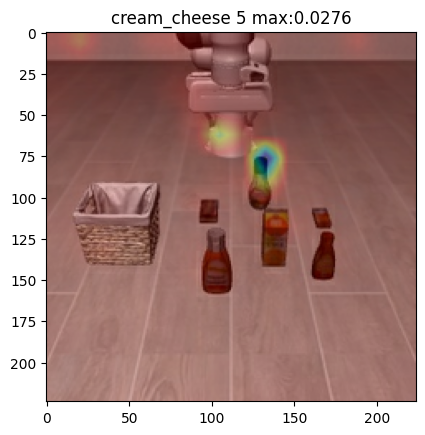

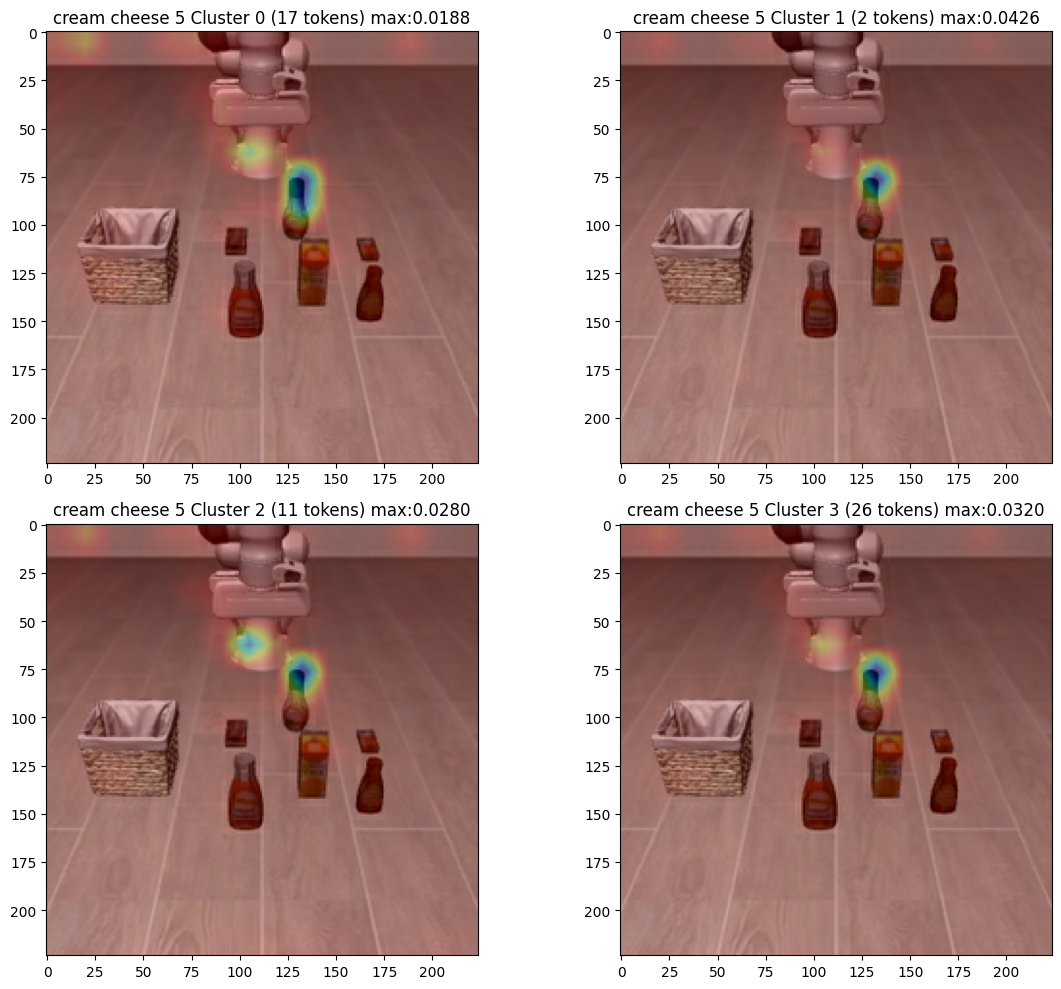

In [102]:
token_info = {
    'image_start': 1,
    'image_end': 257,
    'action_start': len(mean_attention)-57,
    'action_end': len(mean_attention)-1,
}
fig, gini, num_peaks = analyze_multi_object_attention(
    mean_attention.cpu().numpy(), token_info,original_image=img1,object=object,data_index=data_index,idx=1
)

Attention Gini系数: 0.6328
Top-5 patches占据总attention的: 15.0%
发现 34 个attention峰值


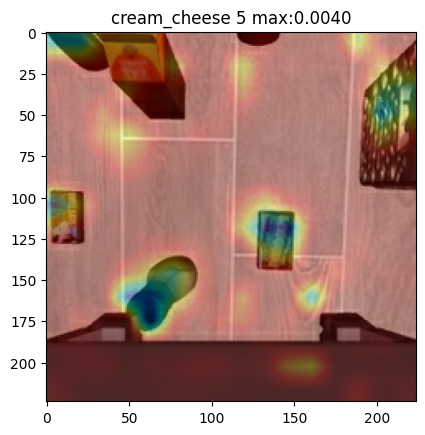

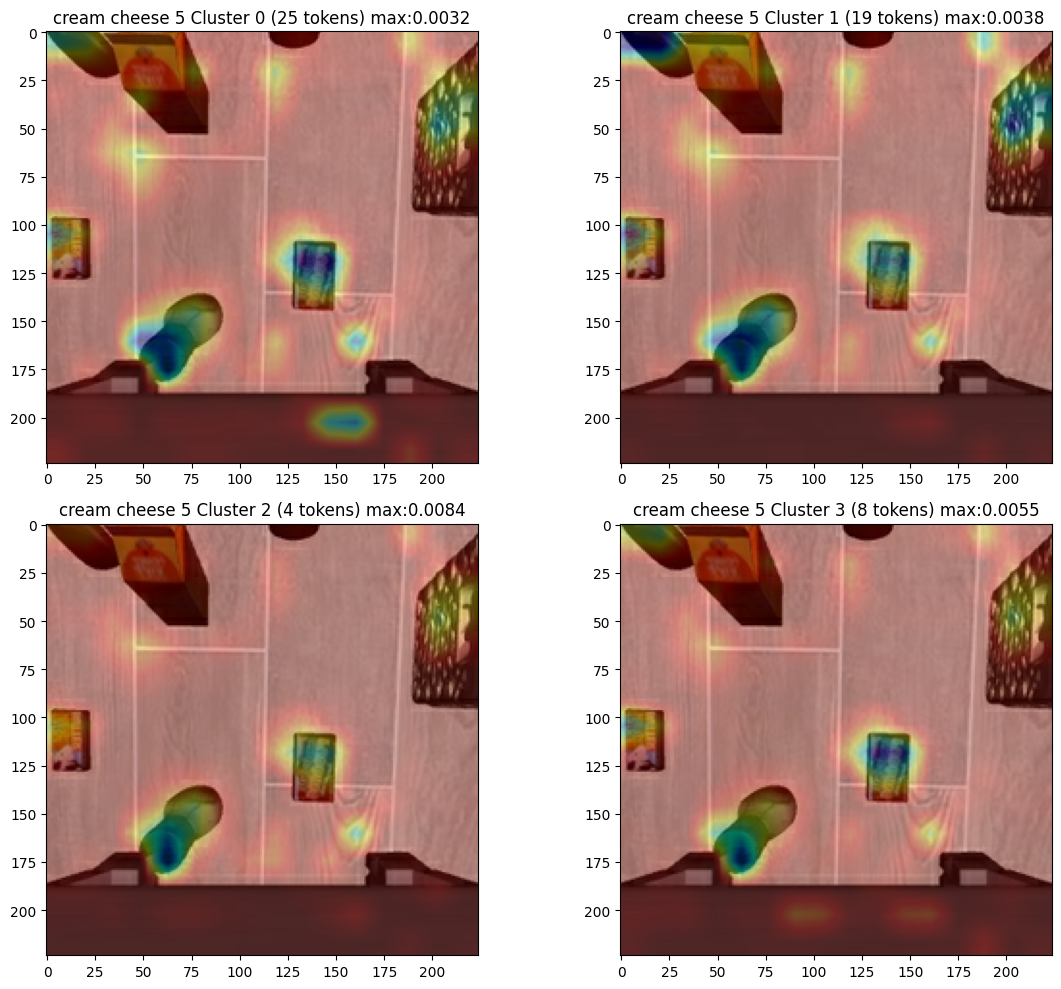

In [103]:
token_info = {
    'image_start': 257,
    'image_end': 513,
    'action_start': len(mean_attention)-57,
    'action_end': len(mean_attention)-1,
}
fig, gini, num_peaks = analyze_multi_object_attention(
    mean_attention.cpu().numpy(), token_info,original_image=img2,object=object,data_index=data_index,idx=2
)